# Card upgrade engine: run report
Run `python -m reco ingest && python -m reco train` first.

In [1]:
import os, sys
from pathlib import Path

sys.path.insert(0, "..")
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from reco import bandit, features, segment, value

DATA = Path(os.environ.get("RECO_DATA", "../data"))
WH = DATA / "warehouse"
scores = pd.read_parquet(DATA / "user_scores.parquet")
vals = pd.read_parquet(DATA / "user_benefit_value.parquet")
reco = pd.read_parquet(DATA / "user_reco.parquet")
user_mcc = pd.read_parquet(WH / "user_mcc.parquet")

## MCC coverage: which IBM MCCs land in which bucket, and which the `dim_mcc` join drops

In [2]:
duckdb.sql(f"""
SELECT mcc, any_value(description) AS description, {features.BUCKET} AS bucket,
       count(*) AS n, round(sum(greatest(amount, 0))) AS spend, any_value(description) IS NULL AS dropped
FROM read_parquet('{WH}/transactions/**/*.parquet') LEFT JOIN '{WH}/dim_mcc.parquet' USING (mcc)
GROUP BY mcc ORDER BY bucket, spend DESC
""").df()

,mcc,description,bucket,n,spend,dropped
0,4829,Money Orders – Wire Transfer,cash_advance,1127454,101625860.0,False
1,5912,Drug Stores and Pharmacies,healthcare,1406579,64798351.0,False
2,8021,Dentists and Orthodontists,healthcare,60145,9441290.0,False
3,8011,Doctors and Physicians (Not Elsewhere Classified),healthcare,45901,8180382.0,False
4,8062,Hospitals,healthcare,6715,4868514.0,False
...,...,...,...,...,...,...
104,3005,BRITISH AIRWAYS,travel,686,550226.0,False
105,3006,JAPAN AIRLINES,travel,643,524917.0,False
106,3007,AIR FRANCE,travel,625,499088.0,False
107,3075,SINGAPORE AIRLINES,travel,626,489967.0,False


## Segmentation: silhouette by k, PCA loadings, cluster profiles

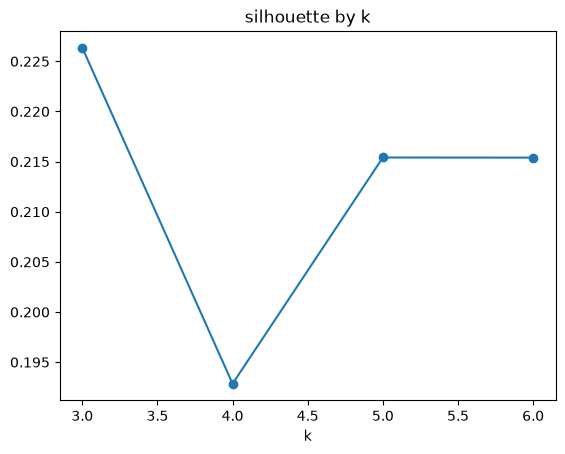

In [3]:
_, embed, _, sil = segment.segment(pd.read_parquet(WH / "user_features.parquet"))
pd.Series(sil).plot(marker="o", title="silhouette by k", xlabel="k");

In [4]:
pca = embed[-1]
print("explained variance:", pca.explained_variance_ratio_.round(3))
pd.DataFrame(pca.components_.T, index=features.FEATURES, columns=[f"PC{i + 1}" for i in range(pca.n_components_)]).round(2)

explained variance: [0.177 0.133 0.113 0.104]


,PC1,PC2,PC3,PC4
recency_days,-0.07,-0.18,-0.30,-0.06
freq_month,0.64,0.00,-0.05,-0.06
spend_month,0.65,0.10,-0.06,-0.08
travel_share,-0.27,0.59,-0.05,-0.15
healthcare_share,-0.03,-0.43,0.24,-0.51
cash_advance_share,0.14,0.02,-0.16,0.70
travel_30d,0.12,0.60,-0.07,-0.29
insufficient_rate,0.16,-0.11,0.39,0.09
fico,0.03,0.14,0.63,0.03
dti,-0.08,-0.16,-0.44,-0.08


In [5]:
scores.groupby("cluster")[features.FEATURES].mean().round(3).assign(users=scores.cluster.value_counts())

,recency_days,freq_month,spend_month,travel_share,healthcare_share,cash_advance_share,travel_30d,insufficient_rate,fico,dti,utilization,users
cluster,,,,,,,,,,,,
baseline,102.086,71.140,3119.991,0.095,0.085,0.060,89.373,0.009,707.367,1.438,0.117,1207
revolver,22.191,143.753,7596.090,0.063,0.068,0.134,331.632,0.012,707.035,1.326,0.239,425
transactor,1.671,75.979,4096.186,0.194,0.055,0.061,1149.255,0.008,720.617,1.262,0.119,368


## Uplift: X-Learner CATE vs simulated true effect

corr(CATE, true tau): 0.752
persuadable share (CATE > 0): 0.752


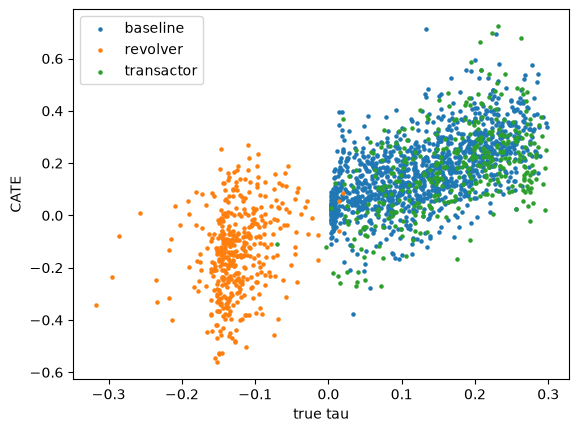

In [6]:
print("corr(CATE, true tau):", round(np.corrcoef(scores.cate, scores.tau)[0, 1], 3))
print("persuadable share (CATE > 0):", round((scores.cate > 0).mean(), 3))
for c, g in scores.groupby("cluster"):
    plt.scatter(g.tau, g.cate, s=5, label=c)
plt.xlabel("true tau"); plt.ylabel("CATE"); plt.legend();

## Benefits: sector spend, best sector by hard value, insurance/subscription evidence

In [7]:
sector_spend = user_mcc.groupby(["user_id", "sector"]).spend_month.sum().unstack(fill_value=0)
print("share of spend in 'other':", round(user_mcc.spend_month[user_mcc.sector == "other"].sum() / user_mcc.spend_month.sum(), 3))
print("insurance/subscription MCCs present:", sorted(set(user_mcc.mcc) & set(features.WATCH_MCCS)) or "none")
sector_spend.join(scores.set_index("user_id").cluster).groupby("cluster").mean().round(0).T

share of spend in 'other': 0.08
insurance/subscription MCCs present: [4814, 4899, 5815, 5816, 6300]


cluster,baseline,revolver,transactor
air,90.0,147.0,254.0
car_rental,45.0,68.0,107.0
cash_advance,179.0,959.0,256.0
dining,213.0,528.0,338.0
entertainment,75.0,143.0,105.0
fuel,243.0,686.0,254.0
groceries,584.0,1453.0,588.0
healthcare,312.0,589.0,272.0
hotel,138.0,211.0,318.0
insurance,63.0,120.0,115.0


In [8]:
best = value.best_per_sector(vals)
top = best.loc[best.groupby("user_id").hard_value_month.idxmax()].merge(scores[["user_id", "cluster"]], on="user_id")
print("premium worth pitching (upgrade_gain_month > 0):", round((reco.upgrade_gain_month > 0).mean(), 3))
pd.crosstab(top.sector, top.cluster).assign(mean_value_month=top.groupby("sector").hard_value_month.mean().round(1))

premium worth pitching (upgrade_gain_month > 0): 0.966


cluster,baseline,revolver,transactor,mean_value_month
sector,,,,
air,487,188,161,24.9
all,507,135,98,19.6
dining,72,83,31,28.6
entertainment,13,0,0,10.0
fuel,2,0,0,11.3
hotel,11,19,64,28.3
telecom_utilities,115,0,14,19.7


## Bandit over sectors: monthly reward vs random, greedy-by-value and oracle (simulated acceptance)

In [9]:
cands = bandit.candidates(vals)
res = pd.DataFrame({n: bandit.simulate(scores, cands, n=n) for n in (500, 2000, 5000)}).T
display(res.assign(regret_per_step=res.oracle - res.bandit).round(2))
reco.groupby("sector").agg(users=("user_id", "size"), value_month=("value_month", "mean"),
                           p_accept=("p_accept", "mean")).round(2).sort_values("users", ascending=False)

,bandit,random,greedy,oracle,regret_per_step
500,7.30,3.37,7.61,7.79,0.50
2000,7.43,3.68,6.81,7.79,0.37
5000,7.56,3.61,6.92,7.81,0.25


,users,value_month,p_accept
sector,,,
all,1500,19.44,0.50
none,425,0.00,0.00
telecom_utilities,36,19.00,0.28
hotel,28,32.53,0.23
entertainment,6,7.91,0.38
dining,3,2.69,0.55
fuel,2,0.96,0.44


## Personas (synthetic, conditioned on behaviour): traits by cluster

In [10]:
personas = pd.read_parquet(DATA / "personas.parquet").merge(scores[["user_id", "cluster"]], on="user_id")
for trait in ("digital", "channel", "motivation", "tone"):
    display(pd.crosstab(personas[trait], personas.cluster, normalize="columns").round(2))

cluster,baseline,revolver,transactor
digital,,,
high,0.27,0.52,0.35
low,0.50,0.30,0.46
medium,0.22,0.18,0.20


cluster,baseline,revolver,transactor
channel,,,
email,0.19,0.17,0.20
in_app,0.15,0.14,0.17
phone,0.31,0.24,0.26
push,0.16,0.30,0.20
sms,0.18,0.15,0.18


cluster,baseline,revolver,transactor
motivation,,,
convenience,0.16,0.34,0.10
savings,0.38,0.49,0.10
security,0.26,0.10,0.12
status,0.20,0.07,0.68


cluster,baseline,revolver,transactor
tone,,,
concise_data,0.30,0.33,0.19
exclusive,0.20,0.15,0.40
friendly,0.25,0.38,0.25
reassuring,0.25,0.15,0.16
